# Exercise description

Implement local search. Local search should use deltas (changes) of the objective function. Do not use trivial implementation with neighbor solution constructed explicitly and the objective function calculated from scratch. On the other hand, do not use more advanced techniques like deltas from previous iterations or candidate moves (we will implement them in future assignments).

## Type of local search
Implement both steepest and greedy version of local search. In greedy version the neighborhood should be browsed in random/randomized order. In the report please describe what kind of randomization was used. Note, that in greedy version, it is not acceptable to evaluate (calculate delta) all moves and them browse them in random order and select the first improving one, because we need to minimize the number of evaluated moves.

## Type of neighborhood
We will need two kinds of moves:
* **intra-route moves** - moves changing the order of nodes within the same set of selected nodes.
* **inter-route moves** - moves changing the set of selected nodes.

As inter-route move use exchange of two nodes one selected one not selected.

For intra-route moves use two options:
* two-nodes exchange,
* two-edges exchange.

As inter-route moves use always nodes-exchange with one selected one not selected.

Note that the whole neighborhood is composed of moves of two kinds inter- and intra-route moves. In the steepest version we should select the best move from the whole neighborhood composed of moves of two types. In the greedy version ideally we should test moves of two kinds in a random order. If you use a simpler randomization do not, for example, start always from moves of a given kind (e.g. always from intra-route moves).

## Type of starting solutions
Use two options:
* Random starting solutions.
* The best greedy construction heuristic (including regret heuristics) from the previous assignments with a random starting node.

Summarizing we have 8 combinations based on three binary options: type of local search (steepest or greedy), type of intra-route moves (nodes or edges exchange), type of starting solutions (random or greedy).

## Computational experiment
Run each of the eight methods 200 times. For random starting solutions use 200 randomly generated solutions. For greedy starting solutions use each of the 200 nodes as the starting node for the greedy heuristic.

## Reporting results
Use table with the following outline:

| | Instance 1 | Instance 2 |
| :--- | :--- | :--- |
| **Method 1** | av (min-max) | av (min-max) |
| **Method 2** | av (min - max) | av (min-max) |

Include also results for all previous methods.

Report two tables one for the values of the objective function and for the running times.

The outline of the report as previously.

extra guidelines

- Do not use methods more advanced than delta
- the evaluations shall show that Greedy is faster than steepest. If not the method is implemented badly
- Describe how we perform the randomization in the report
- Pseudocode for local search should be precise, others very brief (summarized)
- Also add the calculation time of the initial solution
- Improve the visualizations- no red dots at the visited points, the line connecting them shall be black, the points should have the colour indicating their price


## Helpers and parameters

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path('data')
INSTANCES = ['TSPA', 'TSPB']
RNG_SEED = 0
NUM_RUNS = 200

def load_instance(name: str):
    d = np.loadtxt(DATA / f'{name}.csv', delimiter=';', dtype=int)
    xy, costs = d[:, :2], d[:, 2]
    diff = xy[:, None, :] - xy[None, :, :]
    dist = np.rint(np.sqrt((diff ** 2).sum(axis=-1))).astype(int)
    n = len(costs)
    k = (n + 1) // 2
    return {'name': name, 'xy': xy, 'costs': costs, 'dist': dist, 'n': n, 'k': k}

def compute_cost(tour, dist, costs) -> int:
    t = np.asarray(tour, dtype=int)
    return int(dist[t, np.roll(t, -1)].sum() + costs[t].sum())

def check_solution(tour, n: int, k: int):
    t = list(tour)
    if len(t) != k:
        return False, f'length {len(t)} != k={k}'
    if len(set(t)) != k:
        return False, 'duplicate nodes'
    if any(v < 0 or v >= n for v in t):
        return False, 'index out of range'
    return True, 'ok'

problems = {name: load_instance(name) for name in INSTANCES}
rng = np.random.default_rng(RNG_SEED)
print('loaded instances:', {n: (problems[n]['n'], problems[n]['k']) for n in INSTANCES})


loaded instances: {'TSPA': (200, 100), 'TSPB': (200, 100)}


## Constructive heuristics from Labs 1-2 (reused as baselines and as greedy starting solutions)

In [2]:
def random_tour(n: int, k: int, rng: np.random.Generator) -> list[int]:
    selected = rng.choice(n, size=k, replace=False)
    rng.shuffle(selected)
    return [int(v) for v in selected]

def nearest_neighbor_at_end(start: int, distances: np.ndarray, costs: np.ndarray, k: int) -> list[int]:
    n = len(costs)
    tour = [int(start)]
    used = np.zeros(n, bool); used[start] = True
    for _ in range(1, k):
        last = tour[-1]
        cand = np.flatnonzero(~used)
        vals = distances[last, cand] + costs[cand]
        nxt = int(cand[int(np.argmin(vals))])
        tour.append(nxt); used[nxt] = True
    return tour

def nearest_neighbor_anywhere(start: int, distances: np.ndarray, costs: np.ndarray, k: int) -> list[int]:
    n = len(costs)
    tour = [int(start)]
    used = np.zeros(n, bool); used[start] = True
    for _ in range(1, k):
        cand = np.flatnonzero(~used)
        t = np.asarray(tour, dtype=int); m = len(t)
        D = distances[np.ix_(cand, t)]
        best = D[:, 0].astype(np.int64).copy()
        pos = np.zeros(len(cand), dtype=int)
        d_end = D[:, -1]
        upd = d_end < best; best[upd] = d_end[upd]; pos[upd] = m
        if m > 1:
            seg = distances[t[:-1], t[1:]]
            ins = D[:, :-1] + D[:, 1:] - seg[None, :]
            j = np.argmin(ins, axis=1)
            v = ins[np.arange(len(cand)), j]
            upd = v < best; best[upd] = v[upd]; pos[upd] = j[upd] + 1
        best = best + costs[cand]
        i = int(np.argmin(best))
        tour.insert(int(pos[i]), int(cand[i])); used[cand[i]] = True
    return tour

def greedy_cycle(start: int, dist: np.ndarray, costs: np.ndarray, k: int) -> list[int]:
    n = len(costs)
    tour = [int(start)]
    used = np.zeros(n, bool); used[start] = True
    for _ in range(1, k):
        cand = np.flatnonzero(~used)
        t = np.asarray(tour, dtype=int); m = len(t)
        if m == 1:
            delta = 2 * dist[int(start), cand] + costs[cand]
            i = int(np.argmin(delta))
            tour.append(int(cand[i])); used[cand[i]] = True
            continue
        nxt = np.roll(t, -1)
        seg = dist[t, nxt]
        ins = dist[np.ix_(cand, t)] + dist[np.ix_(cand, nxt)] - seg[None, :]
        j = np.argmin(ins, axis=1)
        v = ins[np.arange(len(cand)), j] + costs[cand]
        i = int(np.argmin(v))
        tour.insert(int(j[i]) + 1, int(cand[i])); used[cand[i]] = True
    return tour

def _path_insertion_deltas(cand, t, distances):
    m = len(t)
    D = distances[np.ix_(cand, t)]
    deltas = np.empty((len(cand), m + 1), dtype=np.int64)
    deltas[:, 0] = D[:, 0]
    deltas[:, m] = D[:, -1]
    if m > 1:
        seg = distances[t[:-1], t[1:]]
        deltas[:, 1:m] = D[:, :-1] + D[:, 1:] - seg[None, :]
    return deltas

def _cycle_insertion_deltas(cand, t, dist):
    if len(t) == 1:
        return (2 * dist[int(t[0]), cand])[:, None]
    nxt = np.roll(t, -1)
    seg = dist[t, nxt]
    return dist[np.ix_(cand, t)] + dist[np.ix_(cand, nxt)] - seg[None, :]

def _choose_candidate(deltas, costs_cand, mode, w_regret, w_cost):
    d = deltas + costs_cand[:, None]
    if d.shape[1] == 1:
        best = d[:, 0]
        regret = np.zeros(len(costs_cand), dtype=np.float64)
        best_pos = np.zeros(len(costs_cand), dtype=int)
    else:
        best_pos = np.argmin(d, axis=1)
        best = d[np.arange(len(d)), best_pos]
        part = np.argpartition(d, 1, axis=1)[:, :2]
        v0 = d[np.arange(len(d)), part[:, 0]]
        v1 = d[np.arange(len(d)), part[:, 1]]
        second = np.maximum(v0, v1)
        regret = (second - best).astype(np.float64)
    if mode == 'regret':
        i = int(np.lexsort((best, -regret))[0])
    else:
        score = w_regret * regret - w_cost * best.astype(np.float64)
        i = int(np.lexsort((best, -score))[0])
    return i, int(best_pos[i])

def greedy_2regret_nn(start, distances, costs, k):
    n = len(costs)
    tour = [int(start)]
    used = np.zeros(n, bool); used[start] = True
    for _ in range(1, k):
        cand = np.flatnonzero(~used)
        t = np.asarray(tour, dtype=int)
        i, pos = _choose_candidate(_path_insertion_deltas(cand, t, distances), costs[cand], 'regret', 1.0, 1.0)
        tour.insert(pos, int(cand[i])); used[cand[i]] = True
    return tour

def greedy_2regret_cycle(start, dist, costs, k):
    n = len(costs)
    tour = [int(start)]
    used = np.zeros(n, bool); used[start] = True
    for _ in range(1, k):
        cand = np.flatnonzero(~used)
        t = np.asarray(tour, dtype=int)
        i, pos = _choose_candidate(_cycle_insertion_deltas(cand, t, dist), costs[cand], 'regret', 1.0, 1.0)
        if len(tour) == 1:
            tour.append(int(cand[i]))
        else:
            tour.insert(pos + 1, int(cand[i]))
        used[cand[i]] = True
    return tour

def greedy_weighted_nn(start, distances, costs, k, w_regret=1.0, w_cost=1.0):
    n = len(costs)
    tour = [int(start)]
    used = np.zeros(n, bool); used[start] = True
    for _ in range(1, k):
        cand = np.flatnonzero(~used)
        t = np.asarray(tour, dtype=int)
        i, pos = _choose_candidate(
            _path_insertion_deltas(cand, t, distances), costs[cand], 'weighted', w_regret, w_cost)
        tour.insert(pos, int(cand[i])); used[cand[i]] = True
    return tour

def greedy_weighted_cycle(start, dist, costs, k, w_regret=1.0, w_cost=1.0):
    n = len(costs)
    tour = [int(start)]
    used = np.zeros(n, bool); used[start] = True
    for _ in range(1, k):
        cand = np.flatnonzero(~used)
        t = np.asarray(tour, dtype=int)
        i, pos = _choose_candidate(
            _cycle_insertion_deltas(cand, t, dist), costs[cand], 'weighted', w_regret, w_cost)
        if len(tour) == 1:
            tour.append(int(cand[i]))
        else:
            tour.insert(pos + 1, int(cand[i]))
        used[cand[i]] = True
    return tour

# Greedy starting heuristic: weighted 2-regret + best change with cycle insertion
# (equal weights) - the strongest constructive method from Lab 2.
GREEDY_START_FN = greedy_weighted_cycle


## Local search: delta move definitions (intra-route and inter-route)

In [3]:
def delta_swap_nodes(Dl, Cl, tour, i, j, k):
    """Delta of exchanging the nodes at tour positions i and j (both selected)."""
    if i == j:
        return 0
    if i > j:
        i, j = j, i
    # wrap pair (0, k-1): neighbours of 0 are (k-1, 1), of k-1 are (k-2, 0);
    # the wrap edge (k-1, 0) is unchanged by the swap.
    if i == 0 and j == k - 1:
        return Dl[tour[k - 2]][tour[0]] + Dl[tour[k - 1]][tour[1]] - Dl[tour[k - 2]][tour[k - 1]] - Dl[tour[0]][tour[1]]
    a = tour[(i - 1) % k]
    b = tour[(i + 1) % k]
    c = tour[(j - 1) % k]
    d = tour[(j + 1) % k]
    ti = tour[i]; tj = tour[j]
    if j == i + 1:
        return Dl[a][tj] + Dl[ti][d] - Dl[a][ti] - Dl[tj][d]
    return (Dl[a][tj] + Dl[tj][b] + Dl[c][ti] + Dl[ti][d]
            - Dl[a][ti] - Dl[ti][b] - Dl[c][tj] - Dl[tj][d])

def delta_2opt(Dl, tour, i, j, k):
    """Delta of a 2-opt move: remove edges (i,i+1) and (j,j+1), reverse segment i+1..j."""
    a = tour[i]; b = tour[(i + 1) % k]
    c = tour[j]; d = tour[(j + 1) % k]
    return Dl[a][c] + Dl[b][d] - Dl[a][b] - Dl[c][d]

# list-of-lists copies for fast scalar delta evaluation in the greedy local search
for _name in INSTANCES:
    problems[_name]['Dl'] = problems[_name]['dist'].tolist()
    problems[_name]['Cl'] = problems[_name]['costs'].tolist()


## Local search algorithms: steepest and greedy

In [4]:
def steepest_ls(tour, used, D, C, k, n, intra_kind):
    """Steepest descent: evaluate the whole neighborhood, apply the best improving move.
    intra_kind in {'swap', 'opt'} selects which intra-route move kind is evaluated;
    inter-route moves are always evaluated."""
    t = np.array(tour, dtype=int).copy()
    used = used.copy()
    cost = compute_cost(t, D, C)
    iters = 0
    while True:
        iters += 1
        pos = np.arange(k)
        prev = t[(pos - 1) % k]
        nxt = t[(pos + 1) % k]
        s = t[pos]
        U = np.flatnonzero(~used)
        m = len(U)
        best_delta = 0
        best_move = None
        # inter-route: exchange one selected node with one unselected node
        if m > 0:
            inter = (D[prev[:, None], U[None, :]]
                     + D[U[None, :], nxt[:, None]]
                     - (D[prev, s] + D[s, nxt])[:, None]
                     + C[U][None, :] - C[s][:, None])
            f = int(np.argmin(inter))
            d = int(inter.flat[f])
            if d < best_delta:
                best_delta = d
                best_move = ('inter', f // m, int(U[f % m]))
        # intra-route: two-nodes exchange (only if intra_kind == 'swap')
        if intra_kind == 'swap':
            ii, jj = np.triu_indices(k, 1)
            swap = np.zeros(len(ii), dtype=np.int64)
            non_adj = (jj != ii + 1) & ~((ii == 0) & (jj == k - 1))
            a = t[(ii - 1) % k]; b = t[(ii + 1) % k]
            c = t[(jj - 1) % k]; dd = t[(jj + 1) % k]
            ti = t[ii]; tj = t[jj]
            swap[non_adj] = (D[a[non_adj], tj[non_adj]] + D[tj[non_adj], b[non_adj]]
                             + D[c[non_adj], ti[non_adj]] + D[ti[non_adj], dd[non_adj]]
                             - D[a[non_adj], ti[non_adj]] - D[ti[non_adj], b[non_adj]]
                             - D[c[non_adj], tj[non_adj]] - D[tj[non_adj], dd[non_adj]])
            adj = (jj == ii + 1)
            if adj.any():
                i2 = ii[adj]; j2 = jj[adj]
                a2 = t[(i2 - 1) % k]; d2 = t[(j2 + 1) % k]
                ti2 = t[i2]; tj2 = t[j2]
                swap[adj] = D[a2, tj2] + D[ti2, d2] - D[a2, ti2] - D[tj2, d2]
            wp = (ii == 0) & (jj == k - 1)
            if wp.any():
                swap[wp] = (D[t[k - 2], t[0]] + D[t[k - 1], t[1]]
                            - D[t[k - 2], t[k - 1]] - D[t[0], t[1]])
            f = int(np.argmin(swap)); d = int(swap[f])
            if d < best_delta:
                best_delta = d
                best_move = ('swap', int(ii[f]), int(jj[f]))
        # intra-route: two-edges exchange (2-opt) (only if intra_kind == 'opt')
        if intra_kind == 'opt':
            ii2, jj2 = np.triu_indices(k, 2)
            v2 = ~((ii2 == 0) & (jj2 == k - 1))
            if v2.any():
                i3 = ii2[v2]; j3 = jj2[v2]
                aa = t[i3]; bb = t[(i3 + 1) % k]
                cc = t[j3]; dd2 = t[(j3 + 1) % k]
                twoopt = D[aa, cc] + D[bb, dd2] - D[aa, bb] - D[cc, dd2]
                f = int(np.argmin(twoopt)); d = int(twoopt[f])
                if d < best_delta:
                    best_delta = d
                    best_move = ('2opt', int(i3[f]), int(j3[f]))
        if best_move is None:
            break
        if best_move[0] == 'inter':
            _, p, u = best_move
            used[t[p]] = False; used[u] = True; t[p] = u
        elif best_move[0] == 'swap':
            _, i, j = best_move
            t[i], t[j] = t[j], t[i]
        else:
            _, i, j = best_move
            t[i + 1:j + 1] = t[i + 1:j + 1][::-1]
        cost += best_delta
    return t.tolist(), int(cost), iters

def greedy_ls(tour, used, Dl, Cl, k, n, rng, intra_kind):
    t = list(tour)
    used = used.copy()
    cost = compute_cost(np.array(t), np.array(Dl), np.array(Cl))
    iters = 0
    
    swap_pairs = [(i, j) for i in range(k) for j in range(i + 1, k)]
    opt_pairs = [(i, j) for i in range(k) for j in range(i + 2, k)
                 if not (i == 0 and j == k - 1)]
                 
    while True:
        iters += 1
        improved = False
        kind_order = [0, 1 if intra_kind == 'swap' else 2]
        rng.shuffle(kind_order) 
        U = np.flatnonzero(~used)
        
        for kind in kind_order:
            if kind == 0:
                P_rand = rng.permutation(k)
                U_rand = rng.permutation(U)
                for p in P_rand:
                    p = int(p)
                    prev = t[(p - 1) % k]; nxt = t[(p + 1) % k]; s = t[p]
                    base = -Dl[prev][s] - Dl[s][nxt] - Cl[s]
                    for u in U_rand:
                        u = int(u)
                        d = Dl[prev][u] + Dl[u][nxt] + base + Cl[u]
                        if d < 0:
                            used[s] = False; used[u] = True; t[p] = u
                            cost += d; improved = True
                            break
                    if improved:
                        break
            elif kind == 1:
                rng.shuffle(swap_pairs)
                for i, j in swap_pairs:
                    d = delta_swap_nodes(Dl, Cl, t, i, j, k)
                    if d < 0:
                        t[i], t[j] = t[j], t[i]
                        cost += d; improved = True
                        break
            else:
                rng.shuffle(opt_pairs)
                for i, j in opt_pairs:
                    d = delta_2opt(Dl, t, i, j, k)
                    if d < 0:
                        t[i + 1:j + 1] = reversed(t[i + 1:j + 1])
                        cost += d; improved = True
                        break
            if improved:
                break
        if not improved:
            break
    return t, int(cost), iters


## Computational experiment: eight local-search methods plus previous baselines

In [5]:
results = {}
best_tours = {}
timings = {}
init_times = {}

METHODS_LS = [
    ('steepest_swap_random', 'steepest', 'swap', 'random'),
    ('steepest_opt_random', 'steepest', 'opt', 'random'),
    ('steepest_swap_greedy', 'steepest', 'swap', 'greedy'),
    ('steepest_opt_greedy', 'steepest', 'opt', 'greedy'),
    ('greedy_swap_random', 'greedy', 'swap', 'random'),
    ('greedy_opt_random', 'greedy', 'opt', 'random'),
    ('greedy_swap_greedy', 'greedy', 'swap', 'greedy'),
    ('greedy_opt_greedy', 'greedy', 'opt', 'greedy'),
]

CONSTRUCTIVE = [
    ('random', None),
    ('nn_at_end', nearest_neighbor_at_end),
    ('nn_anywhere', nearest_neighbor_anywhere),
    ('greedy_cycle', greedy_cycle),
    ('greedy_2regret_nn', greedy_2regret_nn),
    ('greedy_2regret_cycle', greedy_2regret_cycle),
    ('greedy_weighted_nn', greedy_weighted_nn),
    ('greedy_weighted_cycle', greedy_weighted_cycle),
]

for name in INSTANCES:
    pr = problems[name]
    n, k, D, C = pr['n'], pr['k'], pr['dist'], pr['costs']
    Dl, Cl = pr['Dl'], pr['Cl']
    results[name] = {}
    best_tours[name] = {}
    timings[name] = {}
    init_times[name] = {}

    # --- constructive baselines (previous methods) ---
    for mname, fn in CONSTRUCTIVE:
        t0 = time.perf_counter()
        if mname == 'random':
            tours = [random_tour(n, k, rng) for _ in range(NUM_RUNS)]
        else:
            tours = [fn(s, D, C, k) for s in range(n)]
        t_build = time.perf_counter() - t0
        vals = np.array([compute_cost(t, D, C) for t in tours])
        results[name][mname] = vals
        best_tours[name][mname] = tours[int(np.argmin(vals))]
        timings[name][mname] = time.perf_counter() - t0
        init_times[name][mname] = t_build
        print(f"{name}/{mname}: min={vals.min()} max={vals.max()} mean={vals.mean():.1f} "
              f"(total={timings[name][mname]:.2f}s init={t_build:.2f}s)")

    # --- eight local-search methods ---
    for mname, ls_kind, intra_kind, start_kind in METHODS_LS:
        t0 = time.perf_counter()
        tours = []
        per_run_init = []
        for run in range(NUM_RUNS):
            if start_kind == 'random':
                ti = time.perf_counter()
                init = random_tour(n, k, rng)
                per_run_init.append(time.perf_counter() - ti)
            else:
                ti = time.perf_counter()
                init = GREEDY_START_FN(run, D, C, k)  # run == starting node index
                per_run_init.append(time.perf_counter() - ti)
            used = np.zeros(n, bool); used[np.array(init)] = True
            if ls_kind == 'steepest':
                tour, cost, iters = steepest_ls(init, used.copy(), D, C, k, n, intra_kind)
            else:
                tour, cost, iters = greedy_ls(init, used.copy(), Dl, Cl, k, n, rng, intra_kind)
            tours.append(tour)
        t_total = time.perf_counter() - t0
        vals = np.array([compute_cost(t, D, C) for t in tours])
        results[name][mname] = vals
        best_tours[name][mname] = tours[int(np.argmin(vals))]
        timings[name][mname] = t_total
        init_times[name][mname] = float(np.mean(per_run_init))
        print(f"{name}/{mname}: min={vals.min()} max={vals.max()} mean={vals.mean():.1f} "
              f"(total={t_total:.2f}s init_run={init_times[name][mname]:.4f}s)")


TSPA/random: min=237157 max=289146 mean=263626.5 (total=0.01s init=0.01s)
TSPA/nn_at_end: min=84362 max=90075 mean=87476.6 (total=0.17s init=0.16s)
TSPA/nn_anywhere: min=72328 max=77022 mean=74347.0 (total=2.11s init=2.11s)
TSPA/greedy_cycle: min=72590 max=75281 mean=73793.4 (total=2.35s init=2.35s)
TSPA/greedy_2regret_nn: min=110950 max=135771 mean=121360.3 (total=5.55s init=5.54s)
TSPA/greedy_2regret_cycle: min=112806 max=128089 mean=120378.8 (total=5.65s init=5.65s)
TSPA/greedy_weighted_nn: min=72419 max=78504 mean=75549.4 (total=4.72s init=4.72s)
TSPA/greedy_weighted_cycle: min=72011 max=75532 mean=73353.5 (total=5.49s init=5.49s)
TSPA/steepest_swap_random: min=82117 max=101055 mean=89958.6 (total=27.03s init_run=0.0001s)
TSPA/steepest_opt_random: min=74006 max=79627 mean=76152.8 (total=13.70s init_run=0.0001s)
TSPA/steepest_swap_greedy: min=71955 max=74861 mean=73021.7 (total=6.49s init_run=0.0288s)
TSPA/steepest_opt_greedy: min=71955 max=74861 mean=73003.8 (total=6.06s init_run=0

## Visualization of the best solutions

IndexError: index 221 is out of bounds for axis 0 with size 200

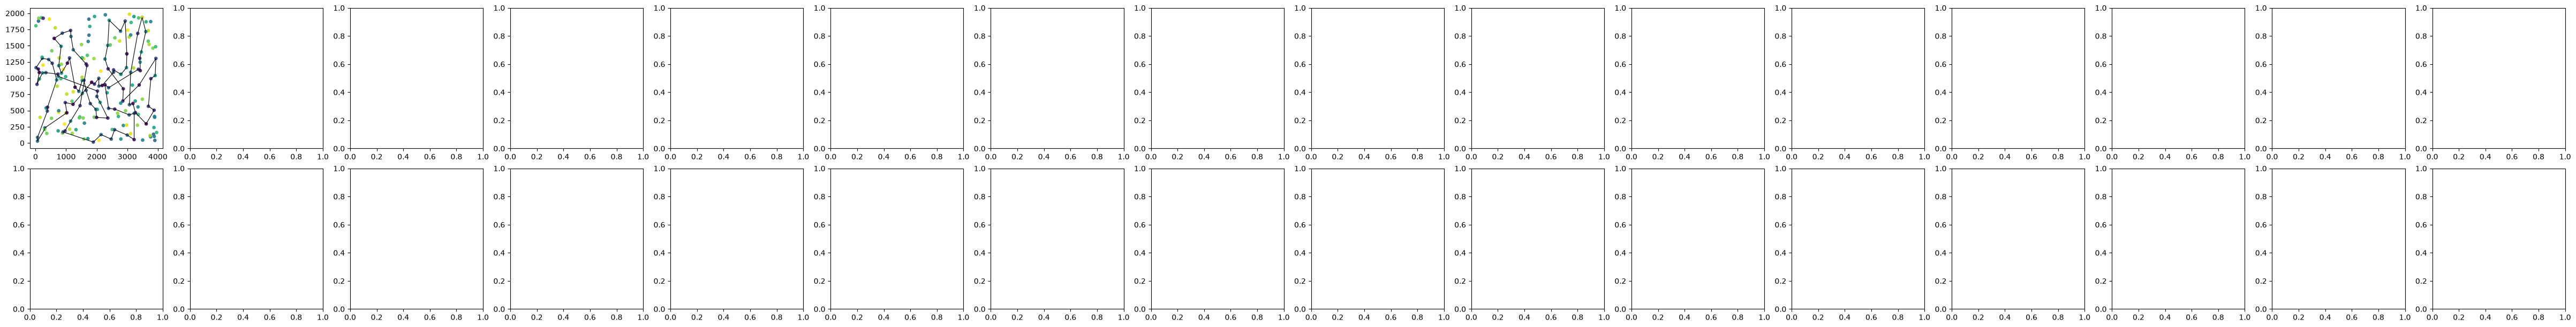

In [6]:
from matplotlib.colors import Normalize

all_costs = np.concatenate([problems[n]['costs'] for n in INSTANCES])
norm = Normalize(vmin=int(all_costs.min()), vmax=int(all_costs.max()))
sm = plt.cm.ScalarMappable(norm=norm, cmap='viridis')

PLOT_METHODS = [m for m, _, _, _ in METHODS_LS] + [m for m, _ in CONSTRUCTIVE]

with plt.style.context('default'):
    fig, axes = plt.subplots(len(INSTANCES), len(PLOT_METHODS), figsize=(3.0 * len(PLOT_METHODS), 6.0),
                             constrained_layout=True)
    fig.patch.set_facecolor('white')
    if len(INSTANCES) == 1:
        axes = np.array([axes])
    for i, name in enumerate(INSTANCES):
        pr = problems[name]
        xy, costs = pr['xy'], pr['costs']
        for j, mname in enumerate(PLOT_METHODS):
            ax = axes[i, j]
            ax.set_facecolor('white')
            tour = best_tours[name][mname]
            t = np.asarray(tour, dtype=int)
            c = compute_cost(t, pr['dist'], pr['costs'])
            ax.scatter(xy[:, 0], xy[:, 1], c=costs, cmap='viridis', norm=norm, s=14, alpha=0.9, zorder=1)
            path = xy[np.append(t, t[0])]
            ax.plot(path[:, 0], path[:, 1], 'k-', lw=0.8, zorder=3)
            ax.scatter(path[:, 0], path[:, 1], c=costs[path.astype(int)], cmap='viridis', norm=norm,
                       s=22, edgecolor='black', linewidth=0.3, zorder=4)
            ax.set_title(f'{name} / {mname}\nbest={c}', fontsize=7)
            ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(sm, ax=axes, location='right', fraction=0.015, pad=0.02, label='node cost')
    plt.show()


## Best solutions as node index lists (0-based)

In [ ]:
for name in INSTANCES:
    pr = problems[name]
    print(f'=== {name} (n={pr["n"]}, k={pr["k"]}) ===')
    for mname in PLOT_METHODS:
        tour = best_tours[name][mname]
        cost = compute_cost(tour, pr['dist'], pr['costs'])
        print(f'{mname}: cost={cost}')
        print(tour)
        print()


## Save best solutions for checking

In [ ]:
from pathlib import Path
OUT = Path('solutions')
OUT.mkdir(exist_ok=True)
for name in INSTANCES:
    for mname in PLOT_METHODS:
        tour = [int(v) for v in best_tours[name][mname]]
        with open(OUT / f'lab3_{name}_{mname}_ids.csv', 'w') as f:
            for idx in tour:
                f.write(f'{idx}\n')
        print(f'saved solutions/lab3_{name}_{mname}_ids.csv')
